In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
# Chargement des données
X, y = fetch_california_housing(return_X_y= True, as_frame= True)


data = X.copy()  
data['MedHouseVal'] = y

In [4]:
# Les 5 premiéres lignes 
data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23,4.53
1,8.30,21.00,6.24,0.97,2401.00,2.11,37.86,-122.22,3.58
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24,3.52
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25,3.41
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25,3.42


In [5]:
# Calculer la matrice de corrélation
corr_mat = data.corr(numeric_only= True)
corr_mat

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.00,-0.12,0.33,-0.06,0.00,0.02,-0.08,-0.02,0.69
HouseAge,-0.12,1.00,-0.15,-0.08,-0.30,0.01,0.01,-0.11,0.11
AveRooms,0.33,-0.15,1.00,0.85,-0.07,-0.00,0.11,-0.03,0.15
AveBedrms,-0.06,-0.08,0.85,1.00,-0.07,-0.01,0.07,0.01,-0.05
Population,0.00,-0.30,-0.07,-0.07,1.00,0.07,-0.11,0.10,-0.02
AveOccup,0.02,0.01,-0.00,-0.01,0.07,1.00,0.00,0.00,-0.02
Latitude,-0.08,0.01,0.11,0.07,-0.11,0.00,1.00,-0.92,-0.14
Longitude,-0.02,-0.11,-0.03,0.01,0.10,0.00,-0.92,1.00,-0.05
MedHouseVal,0.69,0.11,0.15,-0.05,-0.02,-0.02,-0.14,-0.05,1.00


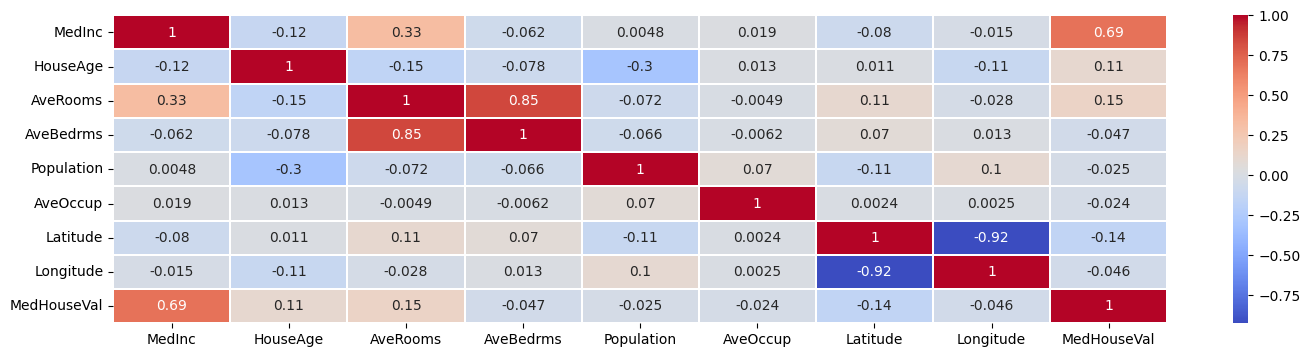

In [6]:
# Plotter la matrice de corrélation
plt.figure(figsize=(17,4))
sns.heatmap(corr_mat, cmap= 'coolwarm', annot= True, linewidths= 0.2)
plt.show()

In [7]:
# Diviser les données en train 80% et test 20%
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train))

16512 16512


In [8]:
# Standariser les données d'entrainement
scaler = StandardScaler()
scaler.fit_transform(X_train)
scaler.fit(X_test)

StandardScaler()

In [9]:
# Initialiser et entrainner le modéle
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [10]:
# Faire une prédiction
y_pred = model.predict(X_test)

In [11]:
# Évaluation du modèle
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n**Évaluation du modèle :**")
print(f"MAE  = {mae:.3f}")
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R²   = {r2:.3f}")


**Évaluation du modèle :**
MAE  = 0.533
MSE  = 0.556
RMSE = 0.746
R²   = 0.576


In [12]:
model.coef_

array([ 4.48674910e-01,  9.72425752e-03, -1.23323343e-01,  7.83144907e-01,
       -2.02962058e-06, -3.52631849e-03, -4.19792487e-01, -4.33708065e-01])

In [13]:
model.intercept_

-37.023277706064064

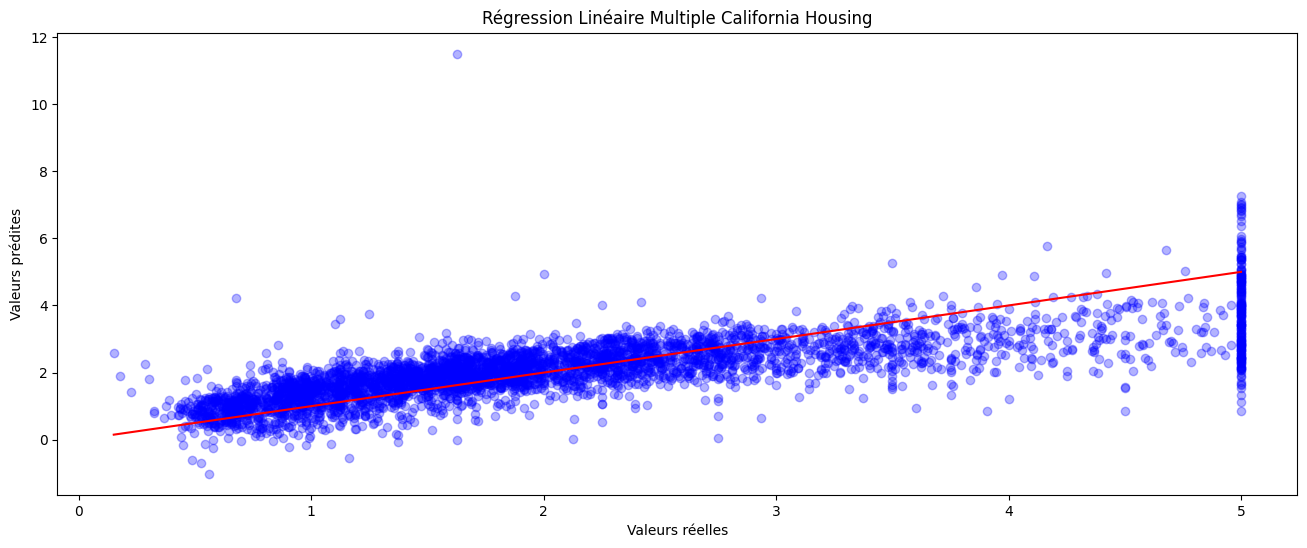

In [14]:
plt.figure(figsize=(16,6))
plt.scatter(y_test, y_pred, alpha=0.3, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Régression Linéaire Multiple California Housing")
plt.show()

In [19]:
# BONUS 

In [15]:
from lazypredict.Supervised import LazyRegressor
model = LazyRegressor()

In [16]:
models, predictions = model.fit(X_train, X_test, y_train, y_test)


  0%|          | 0/42 [00:00<?, ?it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001508 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.071947


In [17]:
models

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
LGBMRegressor,0.84,0.84,0.46,0.28
HistGradientBoostingRegressor,0.84,0.84,0.46,0.83
ExtraTreesRegressor,0.81,0.81,0.50,8.65
RandomForestRegressor,0.80,0.81,0.51,20.58
BaggingRegressor,0.78,0.78,0.53,2.30
MLPRegressor,0.78,0.78,0.54,20.93
GradientBoostingRegressor,0.78,0.78,0.54,5.52
NuSVR,0.73,0.73,0.59,23.43
SVR,0.73,0.73,0.60,20.36
